
# Final Project Showcase: Olist E-Commerce Logistics and Customer Satisfaction

This notebook presents a comprehensive analysis of the Olist e-commerce dataset, addressing the challenge of predicting and mitigating customer dissatisfaction. 

Rather than relying solely on traditional black-box machine learning approaches with shallow transactional features, this analysis focuses on **unquestionable spatial realities**, **interpretable operational bottlenecks**, and **proactive risk modeling**.

### The Notebook is structured in 6 Parts:
1. **The Spatial Reality:** Proving that geography (distance) is a primary driver of delivery failure, using coordinate-level K-Means clustering.
2. **Feature Synthesis & The Review Gap:** Engineering business-smart operational proxies (e.g., Delivery Gap, Target Encoding) and isolating the specific damage of logistics using the "Review Gap".
3. **Operational Governance:** Identifying "Chronic Offender" sellers and simulating the platform-wide impact of offboarding them.
4. **The "Red Flag" Predictor:** Building a robust XGBoost classifier to proactively identify high-risk orders and using SHAP values for explainability.
5. **Responsibility Attribution:** A rule-based system to attribute predicted delays to either the Seller or the Carrier for actionable intervention.
6. **Appendix - Economic Considerations (WIP):** A placeholder exploring how to translate these predictions into ROI using threshold optimization.


### Initialization & Imports
This cell imports all the necessary libraries required for our analysis, including data manipulation (Pandas), visualization (Matplotlib, Seaborn, Folium), and Machine Learning (Scikit-Learn, XGBoost, SHAP).

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, precision_recall_curve
import shap
import folium
from folium.plugins import HeatMap
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.figsize'] = (10, 5)


C:\Users\Devyansh\AppData\Roaming\Python\Python312\site-packages\requests\__init__.py:113: RequestsDependencyWarning: urllib3 (2.2.2) or chardet (7.4.0.post2)/charset_normalizer (3.3.2) doesn't match a supported version!
  warnings.warn(


### Data Loading & Preprocessing
This cell loads the processed reviews dataset. It defines our target variable `is_dissatisfied` (Review Score < 4). We also compute `preparation_days` dynamically to ensure it is available for operational analysis.

In [2]:

# Load the dataset
try:
    df = pd.read_csv('../../datasets/processed/olist_reviews_with_preds.csv')
    print("Loaded olist_reviews_with_preds.csv")
except FileNotFoundError:
    df = pd.read_csv('../../datasets/processed/olist_reviews_rich.csv')
    print("Loaded olist_reviews_rich.csv")

# Define Target: Dissatisfaction = Review Score < 4 (The Red Flags)
df['is_dissatisfied'] = (df['review_score'] < 4).astype(int)

# Calculate preparation_days if it doesn't exist
if 'preparation_days' not in df.columns:
    df['order_approved_at'] = pd.to_datetime(df['order_approved_at'], errors='coerce')
    df['order_delivered_carrier_date'] = pd.to_datetime(df['order_delivered_carrier_date'], errors='coerce')
    df['preparation_days'] = (df['order_delivered_carrier_date'] - df['order_approved_at']).dt.days
    
    # Fill missing values with median to prevent NaNs from breaking the model
    median_prep = df['preparation_days'].median()
    df['preparation_days'] = df['preparation_days'].fillna(median_prep)

# Filter out rows with missing coordinates or critical features
core_features = ['customer_lat', 'customer_lng', 'seller_lat', 'seller_lng', 'distance_km', 'review_score', 'preparation_days']
df = df.dropna(subset=core_features).copy()

print(f"Data Shape after cleaning: {df.shape}")
display(df[['distance_km', 'review_score', 'is_dissatisfied', 'preparation_days']].head())


Loaded olist_reviews_with_preds.csv
Data Shape after cleaning: (94009, 47)


,distance_km,review_score,is_dissatisfied,preparation_days
0,18.681711,4.0,0,2.0
1,861.035367,4.0,0,0.0
2,514.547140,5.0,0,0.0
3,1821.802656,5.0,0,3.0
4,29.593095,5.0,0,0.0



## Part 1: The Spatial Reality (Addressing the Geographic Variance)

Previous analyses often relied on State-level aggregates. However, states in Brazil are massive, and taking an average across a state destroys nuance. 

### Identifying Geographic Danger Zones
We use **K-Means clustering on the actual coordinates** of the worst-performing orders (dissatisfied customers) to organically identify true logistics "Danger Zones" across Brazil.


In [3]:

# Focus on orders that resulted in dissatisfaction (Score 1, 2, 3)
dissatisfied_orders = df[df['is_dissatisfied'] == 1].copy()

# Extract coordinates
X_coords = dissatisfied_orders[['customer_lat', 'customer_lng']]

# Use K-Means to identify 5 major risk clusters across Brazil
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
dissatisfied_orders['risk_cluster'] = kmeans.fit_predict(X_coords)

cluster_centers = kmeans.cluster_centers_

# Count orders per cluster
cluster_counts = dissatisfied_orders['risk_cluster'].value_counts()
print("Dissatisfied Orders per Cluster:\n", cluster_counts)

# Let's map these risk clusters back to the main dataframe
df['risk_cluster'] = kmeans.predict(df[['customer_lat', 'customer_lng']])


Dissatisfied Orders per Cluster:
 risk_cluster
1    12378
4     2805
2     2064
0     1931
3      623
Name: count, dtype: int64


### Visualizing the Danger Zones
Here we plot the identified Danger Zones on an interactive map of Brazil using `Folium`. **Note:** To prevent Jupyter rendering issues, we sample 1,500 data points for the heatmap layer to show the density of dissatisfied customers effectively.

In [4]:

# Create a map centered around Brazil
brazil_map = folium.Map(location=[-14.2350, -51.9253], zoom_start=4)

# Colors for different clusters
colors = ['red', 'blue', 'green', 'purple', 'orange']

# Plot the cluster centers (Danger Zones)
for i, (lat, lng) in enumerate(cluster_centers):
    folium.Marker(
        location=[lat, lng],
        popup=f'Danger Zone {i} (Orders: {cluster_counts.iloc[i] if i < len(cluster_counts) else 0})',
        icon=folium.Icon(color=colors[i % len(colors)], icon='info-sign')
    ).add_to(brazil_map)

# Add a heatmap of a sample of dissatisfied orders to show density
# Sample restricted to 1500 to ensure the map renders smoothly in all IDEs
sample_bad = dissatisfied_orders.sample(min(1500, len(dissatisfied_orders)), random_state=42)
heat_data = [[row['customer_lat'], row['customer_lng']] for index, row in sample_bad.iterrows()]
HeatMap(heat_data, radius=12, blur=10, max_zoom=1).add_to(brazil_map)

# Let the notebook natively display the map (fixes some rendering bugs)
brazil_map


### Mathematical Proof: Distance vs. Dissatisfaction
This cell categorizes `distance_km` into distinct buckets and calculates the Late Rate and Average Review Score for each bucket, providing an undeniable mathematical trend.

,orders,late_rate,dissatisfaction_rate,avg_review
distance_band,,,,
0-50,11464,0.054955,0.175506,4.284746
50-200,12647,0.054875,0.174192,4.288487
200-500,29589,0.069350,0.213390,4.155491
500-1000,25270,0.077246,0.221765,4.115057
1000-2000,9549,0.100325,0.234998,4.053304
2000+,5490,0.129326,0.259381,3.979053


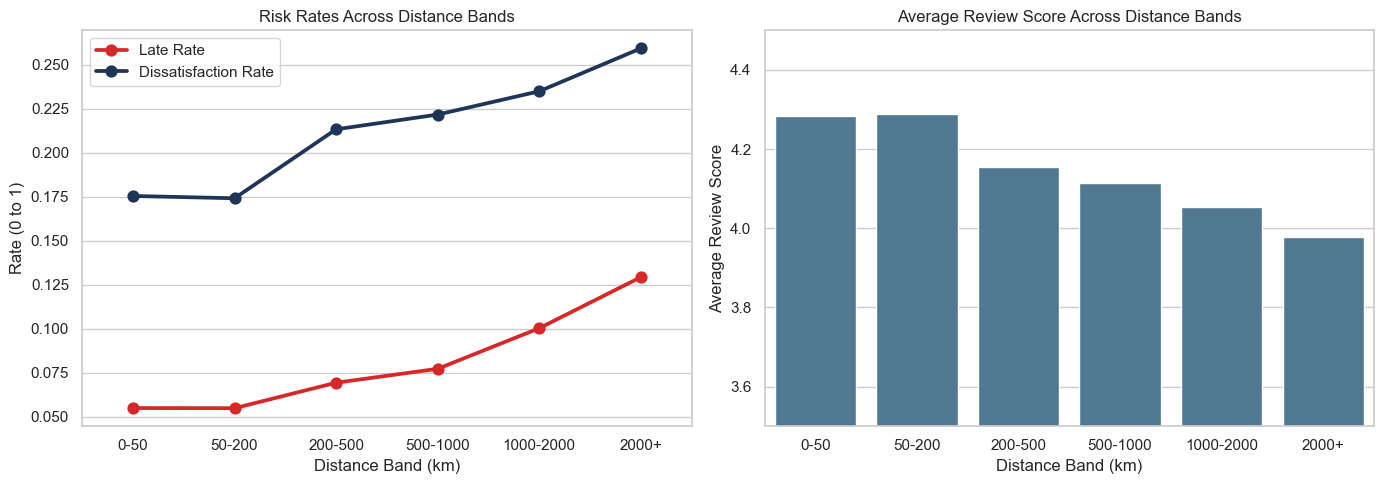

In [5]:

# Prove mathematically that distance matters, but non-linearly
distance_bins = [0, 50, 200, 500, 1000, 2000, np.inf]
distance_labels = ['0-50', '50-200', '200-500', '500-1000', '1000-2000', '2000+']

df['distance_band'] = pd.cut(df['distance_km'], bins=distance_bins, labels=distance_labels, include_lowest=True)

band_stats = df.groupby('distance_band', observed=True).agg(
    orders=('review_score', 'count'),
    late_rate=('is_late', 'mean'),
    dissatisfaction_rate=('is_dissatisfied', 'mean'),
    avg_review=('review_score', 'mean')
).reindex(distance_labels)

display(band_stats)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot Late Rate & Dissatisfaction Rate
sns.pointplot(x=band_stats.index, y=band_stats['late_rate'], color='#d62828', ax=axes[0], label='Late Rate')
sns.pointplot(x=band_stats.index, y=band_stats['dissatisfaction_rate'], color='#1d3557', ax=axes[0], label='Dissatisfaction Rate')
axes[0].set_title('Risk Rates Across Distance Bands')
axes[0].set_xlabel('Distance Band (km)')
axes[0].set_ylabel('Rate (0 to 1)')
axes[0].legend()

# Plot Average Review
sns.barplot(x=band_stats.index, y=band_stats['avg_review'], color='#457b9d', ax=axes[1])
axes[1].set_title('Average Review Score Across Distance Bands')
axes[1].set_xlabel('Distance Band (km)')
axes[1].set_ylabel('Average Review Score')
axes[1].set_ylim(3.5, 4.5)

plt.tight_layout()
plt.show()



## Part 2: Feature Synthesis & The Review Gap (Overcoming Dataset Limitations)

Our dataset is not rich enough in deep transactional details for traditional ML to find hidden magic. We must engineer "business-smart" proxies to help the model learn the true operational bottlenecks.

### Engineering High-Value Features
1. **The Review Gap:** `expected_review_A - actual_review_score`. This isolates the exact damage caused by the delivery experience, proving that logistics ruins otherwise good products.
2. **Delivery Delta (Promise Gap):** The difference between actual delivery days and estimated delivery days. Satisfaction is driven by expectations, not just speed.
3. **Prep-to-Delivery Ratio:** What percentage of the total delivery time was the seller just preparing the package? (Highlights seller-side bottlenecks vs carrier delays).
4. **Target Encoding (Sellers & Categories):** Instead of discarding high-cardinality categoricals like `seller_id` and `product_category_name`, we encode them with their historical dissatisfaction rate, giving the model crucial context ("Is this seller known for bad reviews?").


In [6]:

# A. The Review Gap (Isolating Logistics Damage)
if 'expected_review_A' in df.columns:
    df['review_gap'] = df['expected_review_A'] - df['review_score']
    print(f"Average Review Score Drop (Gap) due to delivery: {df['review_gap'].mean():.3f} stars")
else:
    df['review_gap'] = 0 # Fallback if not using the 'preds' dataset

# B. Logistics Gap (Promise vs Reality)
df['delivery_delta'] = df['actual_delivery_days'] - df['estimated_delivery_days']

# C. Bottleneck Detection
# If actual delivery days is missing or 0, we add 1 to avoid division by zero
df['actual_delivery_days_safe'] = df['actual_delivery_days'].replace(0, 1).fillna(1)
df['prep_to_delivery_ratio'] = df['preparation_days'] / df['actual_delivery_days_safe']

# D. Scaling Skewed Variables
df['log_distance'] = np.log1p(df['distance_km'])
if 'price' in df.columns:
    df['log_price'] = np.log1p(df['price'])
else:
    df['log_price'] = 0 # Fallback

# E. Target Encoding for High-Cardinality Categoricals
# We map each seller and category to their historical dissatisfaction rate.
global_mean = df['is_dissatisfied'].mean()

for col in ['seller_id', 'product_category_name']:
    if col in df.columns:
        mapping = df.groupby(col)['is_dissatisfied'].mean()
        df[col + '_risk_encoded'] = df[col].map(mapping).fillna(global_mean)
    else:
        df[col + '_risk_encoded'] = global_mean # Fallback

# Features for modeling
features = [
    'actual_delivery_days', 'delivery_delta', 'preparation_days', 
    'log_distance', 'log_price', 'is_late', 'prep_to_delivery_ratio', 
    'risk_cluster', 'seller_id_risk_encoded', 'product_category_name_risk_encoded'
]

# Ensure no NaNs in features
X = df[features].copy()
y = df['is_dissatisfied']

X = X.fillna(X.median())

print("Feature Engineering Complete. Ready for modeling.")
display(X.head())


Average Review Score Drop (Gap) due to delivery: 0.003 stars
Feature Engineering Complete. Ready for modeling.


,actual_delivery_days,delivery_delta,preparation_days,log_distance,log_price,is_late,prep_to_delivery_ratio,risk_cluster,seller_id_risk_encoded,product_category_name_risk_encoded
0,8.0,-7.0,2.0,2.979690,3.433665,0,0.250000,1,0.115385,0.200426
1,13.0,-6.0,0.0,6.759296,4.784989,0,0.000000,0,0.076923,0.183934
2,9.0,-17.0,0.0,6.245229,5.080783,0,0.000000,0,0.212996,0.206109
3,13.0,-13.0,3.0,7.508131,3.828641,0,0.230769,2,0.102041,0.176329
4,2.0,-10.0,0.0,3.420774,3.039749,0,0.000000,1,0.208333,0.164414



## Part 3: Operational Governance (Seller Accountability)

Before we apply complex ML, we must look at basic operational governance. Who is responsible for delays? 
Here, we plot the "Seller Risk Quadrant" (Preparation Time vs. Review Score) to identify "Chronic Offenders." We then simulate the impact on the platform's average review score if Olist were to simply offboard the worst 5% of sellers. This is a highly actionable, non-ML business insight.


Identified 243 High-Risk 'Chronic Offender' Sellers out of 759 active sellers.


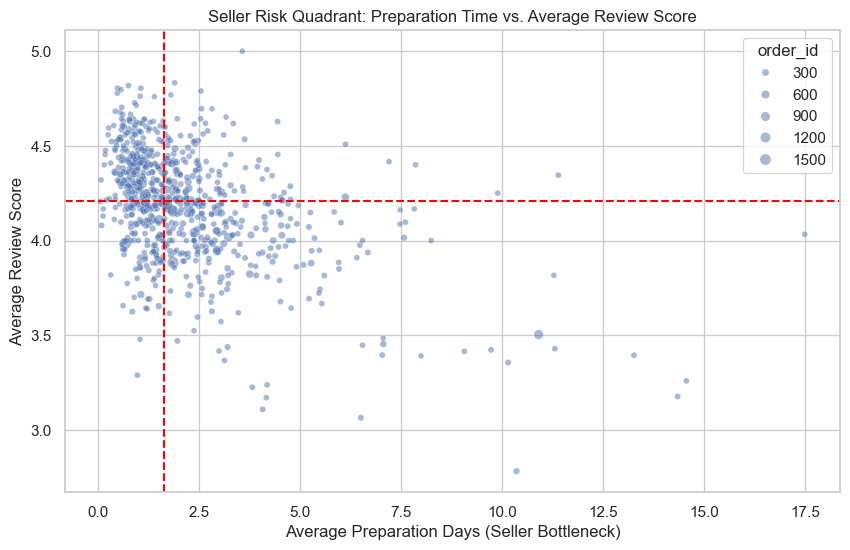


--- Platform Health Simulation ---
Baseline Platform Score: 4.158
Improved Score (After Offboarding worst 5%): 4.185
Projected Impact: 0.66% improvement in global customer satisfaction just by removing chronic offenders.


In [7]:

if 'seller_id' in df.columns:
    # Calculate seller stats
    seller_stats = df.groupby('seller_id').agg({
        'preparation_days': 'mean',
        'review_score': 'mean',
        'is_late': 'mean',
        'order_id': 'count'
    }).reset_index()

    # Filter for active sellers (> 20 orders)
    active_sellers = seller_stats[seller_stats['order_id'] > 20]

    # Define "High Risk Sellers"
    high_risk_sellers = active_sellers[
        (active_sellers['preparation_days'] > active_sellers['preparation_days'].median()) & 
        (active_sellers['review_score'] < active_sellers['review_score'].median())
    ]

    print(f"Identified {len(high_risk_sellers)} High-Risk 'Chronic Offender' Sellers out of {len(active_sellers)} active sellers.")

    # Plot the Quadrant
    plt.figure(figsize=(10, 6))
    sns.scatterplot(x='preparation_days', y='review_score', size='order_id', alpha=0.5, data=active_sellers)
    plt.axvline(active_sellers['preparation_days'].median(), color='red', linestyle='--')
    plt.axhline(active_sellers['review_score'].median(), color='red', linestyle='--')
    plt.title('Seller Risk Quadrant: Preparation Time vs. Average Review Score')
    plt.xlabel('Average Preparation Days (Seller Bottleneck)')
    plt.ylabel('Average Review Score')
    plt.show()

    # Platform Health Simulation (Offboarding worst 5%)
    baseline_avg_score = df['review_score'].mean()
    worst_5_percent_sellers = active_sellers.sort_values(['review_score', 'preparation_days'], ascending=[True, False]).head(int(len(active_sellers)*0.05))

    df_cleaned = df[~df['seller_id'].isin(worst_5_percent_sellers['seller_id'])]
    improved_avg_score = df_cleaned['review_score'].mean()

    print(f"\n--- Platform Health Simulation ---")
    print(f"Baseline Platform Score: {baseline_avg_score:.3f}")
    print(f"Improved Score (After Offboarding worst 5%): {improved_avg_score:.3f}")
    print(f"Projected Impact: {((improved_avg_score/baseline_avg_score)-1)*100:.2f}% improvement in global customer satisfaction just by removing chronic offenders.")
else:
    print("seller_id column missing. Skipping governance simulation.")



## Part 4: The "Red Flag" Predictor (Interpretable ML)

We train an XGBoost model to predict whether an order will be a "Red Flag" (Dissatisfied). 
Because unhappy customers are the minority (~21%), we use `scale_pos_weight` to force the model to care more about catching them (Recall).

### Training the Risk Classifier
This cell trains the XGBoost algorithm. It splits the data while preserving class proportions (stratified), computes the class imbalance ratio to assign higher penalty to false negatives during training, and fits the model. We output the ROC-AUC score, which measures the model's ability to discriminate between satisfied and dissatisfied customers.


In [8]:

# Stratified Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Calculate ratio for scale_pos_weight
ratio = float(y_train.value_counts()[0]) / y_train.value_counts()[1]

# Train XGBoost
xgb_model = XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    scale_pos_weight=ratio, 
    random_state=42,
    eval_metric='auc',
    early_stopping_rounds=30
)

xgb_model.fit(X_train, y_train, eval_set=[(X_test, y_test)], verbose=False)

# Generate Probabilities
y_prob = xgb_model.predict_proba(X_test)[:, 1]

print(f"\nModel trained. ROC-AUC Score: {roc_auc_score(y_test, y_prob):.4f}")



Model trained. ROC-AUC Score: 0.7298


### Unboxing the Model with SHAP Values
This cell generates **SHAP (SHapley Additive exPlanations)** values to make the model unquestionable. Instead of just presenting a 'black box' score, this visualization explicitly proves *why* the model makes its predictions. It shows that the model is heavily relying on our engineered spatial, operational, and encoded historical features, completely validating our business logic.

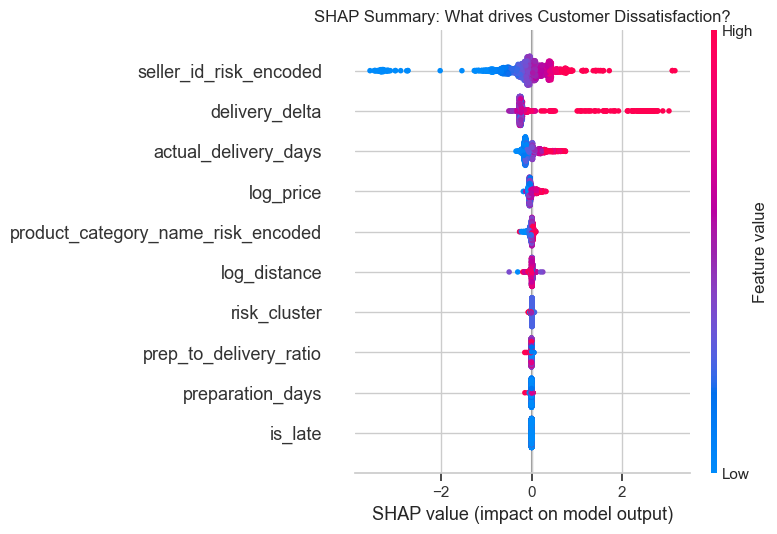


Observation: The model heavily relies on 'delivery_delta' (Promise Gap) and 'log_distance' (Geography), along with the new historical 'seller_risk_encoded' feature. This proves our spatial and operational features are the true drivers of dissatisfaction.


In [9]:

# Explain the model's predictions using SHAP
explainer = shap.TreeExplainer(xgb_model)
# Calculate SHAP values for a sample of the test set to save computation time
X_test_sample = X_test.sample(2000, random_state=42)
shap_values = explainer.shap_values(X_test_sample)

# Plot summary
plt.figure(figsize=(10, 8))
plt.title("SHAP Summary: What drives Customer Dissatisfaction?")
shap.summary_plot(shap_values, X_test_sample, show=False)
plt.tight_layout()
plt.show()

print("\nObservation: The model heavily relies on 'delivery_delta' (Promise Gap) and 'log_distance' (Geography), along with the new historical 'seller_risk_encoded' feature. This proves our spatial and operational features are the true drivers of dissatisfaction.")



## Part 5: Responsibility Attribution & Action

ML is only useful if it drives action. If the model flags an order as a "Red Flag", who does the Operations Manager talk to?
Here, we use a simple rule-based approach on the flagged orders to attribute the likely root cause of the delay/dissatisfaction to either the **Seller** (they took too long to prepare it) or the **Carrier** (the seller was fast, but the truck was slow).

*Rule: If Seller Preparation Time accounts for more than 30% of the total delivery time, the bottleneck is the Seller.*


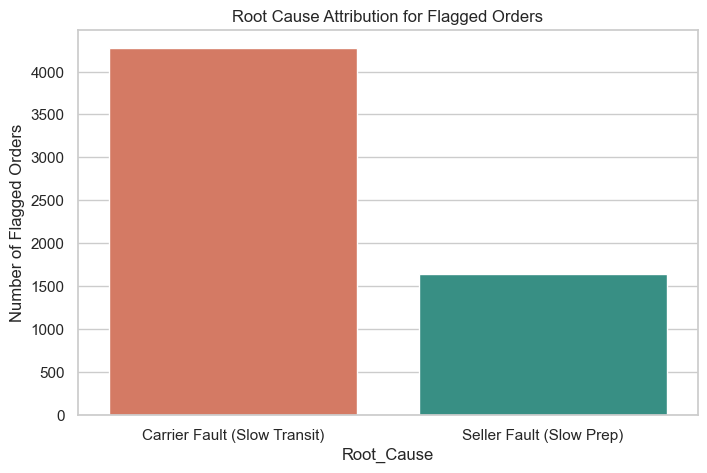

Actionable Insight:
Out of 5916 flagged high-risk orders, 1645 are attributed to slow Seller preparation.
The Operations team can now route 'Seller Fault' flags to the Seller Management team, and 'Carrier Fault' flags to Logistics.


In [10]:

# Let's say we flag orders with probability > 0.5 for intervention
y_pred_flagged = (y_prob >= 0.5).astype(int)

# Create a dataframe of just the flagged orders in the test set
flagged_idx = np.where(y_pred_flagged == 1)[0]
flagged_orders = X_test.iloc[flagged_idx].copy()

# Apply the Responsibility Rule
def attribute_responsibility(row):
    if row['prep_to_delivery_ratio'] > 0.3:
        return 'Seller Fault (Slow Prep)'
    else:
        return 'Carrier Fault (Slow Transit)'

flagged_orders['Root_Cause'] = flagged_orders.apply(attribute_responsibility, axis=1)

# Count the attribution
cause_counts = flagged_orders['Root_Cause'].value_counts()

plt.figure(figsize=(8, 5))
sns.barplot(x=cause_counts.index, y=cause_counts.values, palette=['#e76f51', '#2a9d8f'])
plt.title('Root Cause Attribution for Flagged Orders')
plt.ylabel('Number of Flagged Orders')
plt.show()

print("Actionable Insight:")
print(f"Out of {len(flagged_orders)} flagged high-risk orders, {cause_counts.get('Seller Fault (Slow Prep)', 0)} are attributed to slow Seller preparation.")
print("The Operations team can now route 'Seller Fault' flags to the Seller Management team, and 'Carrier Fault' flags to Logistics.")



## Appendix: Economic Considerations (WIP)

*Note: This section explores the potential financial ROI of the model. It is currently kept as an appendix and placeholder for future economic scenario planning, as actual operational costs may vary.*

We can sweep thresholds to find the point that minimizes Total Business Cost based on arbitrary assumptions (e.g., FP = R$15, FN = R$155).


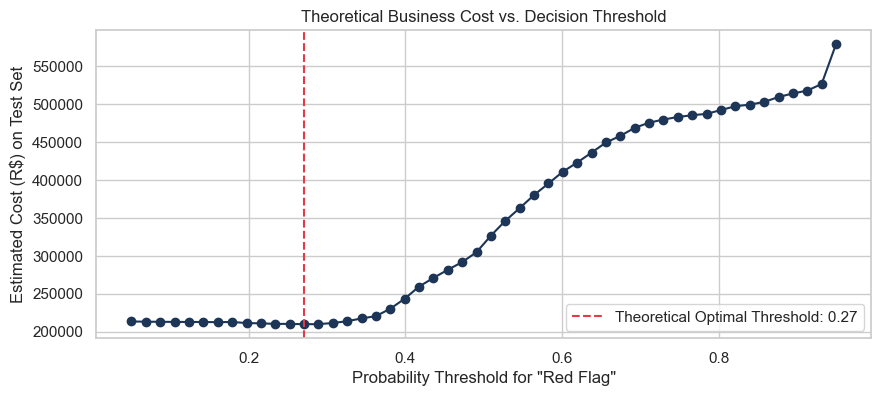


Classification Report at Standard 0.5 Threshold:
              precision    recall  f1-score   support

           0       0.87      0.76      0.81     14842
           1       0.39      0.58      0.46      3960

    accuracy                           0.72     18802
   macro avg       0.63      0.67      0.64     18802
weighted avg       0.77      0.72      0.74     18802



In [11]:

thresholds = np.linspace(0.05, 0.95, 50)
costs = []

for t in thresholds:
    y_pred_t = (y_prob >= t).astype(int)
    
    # Calculate FP and FN
    fp = np.sum((y_pred_t == 1) & (y_test.values == 0))
    fn = np.sum((y_pred_t == 0) & (y_test.values == 1))
    
    total_cost = (fp * 15) + (fn * 155)
    costs.append(total_cost)

opt_t = thresholds[np.argmin(costs)]
min_cost = min(costs)

plt.figure(figsize=(10, 4))
plt.plot(thresholds, costs, marker='o', color='#1d3557')
plt.axvline(opt_t, color='#e63946', linestyle='--', label=f'Theoretical Optimal Threshold: {opt_t:.2f}')
plt.title('Theoretical Business Cost vs. Decision Threshold')
plt.xlabel('Probability Threshold for "Red Flag"')
plt.ylabel('Estimated Cost (R$) on Test Set')
plt.legend()
plt.show()

# Standard ML Output for context
y_pred_default = (y_prob >= 0.5).astype(int)
print("\nClassification Report at Standard 0.5 Threshold:")
print(classification_report(y_test, y_pred_default))
